Step 1 : Dataset exploration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# adjust the path if your zip is in another Drive folder
ZIP = "/content/drive/MyDrive/DL_project/RoadAnomaly.zip"
!ls -l "$ZIP"

Mounted at /content/drive
-rw------- 1 root root 13340595 Oct 17 21:21 /content/drive/MyDrive/DL_project/RoadAnomaly.zip


# Objective 1: Dataset exploration
Dataset structure, image/mask correspondence, category distribution and class imbalance.

In [ ]:
!unzip -q -o "$ZIP" -d /content/data
ROOT = "/content/data/RoadAnomaly"

import glob
print("images:", len(glob.glob(f"{ROOT}/frames/*.webp")))
print("masks :", len(glob.glob(f"{ROOT}/frames/*.labels/labels_semantic.png")))

images: 60
masks : 60


In [ ]:
import os, json, numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

frames = json.load(open(f"{ROOT}/frame_list.json"))
rows = []
for f in frames:
    name = os.path.splitext(f)[0]
    img_p = f"{ROOT}/frames/{name}.webp"
    msk_p = f"{ROOT}/frames/{name}.labels/labels_semantic.png"
    m = np.array(Image.open(msk_p))
    w, h = Image.open(img_p).size
    rows.append(dict(name=name, img=img_p, mask=msk_p, w=w, h=h,
                     category=name.split("_")[0].rstrip("0123456789"),
                     anomaly_frac=(m == 2).mean(),
                     mask_values=tuple(np.unique(m))))
df = pd.DataFrame(rows)
print(df.shape)
print(df.category.value_counts())
print(df[["w","h"]].drop_duplicates())
print(df.mask_values.value_counts())

(60, 8)
category
animals      31
obstacles    15
cones         8
lost          3
vehicle       3
Name: count, dtype: int64
      w    h
0  1280  720
mask_values
(0, 2)    60
Name: count, dtype: int64


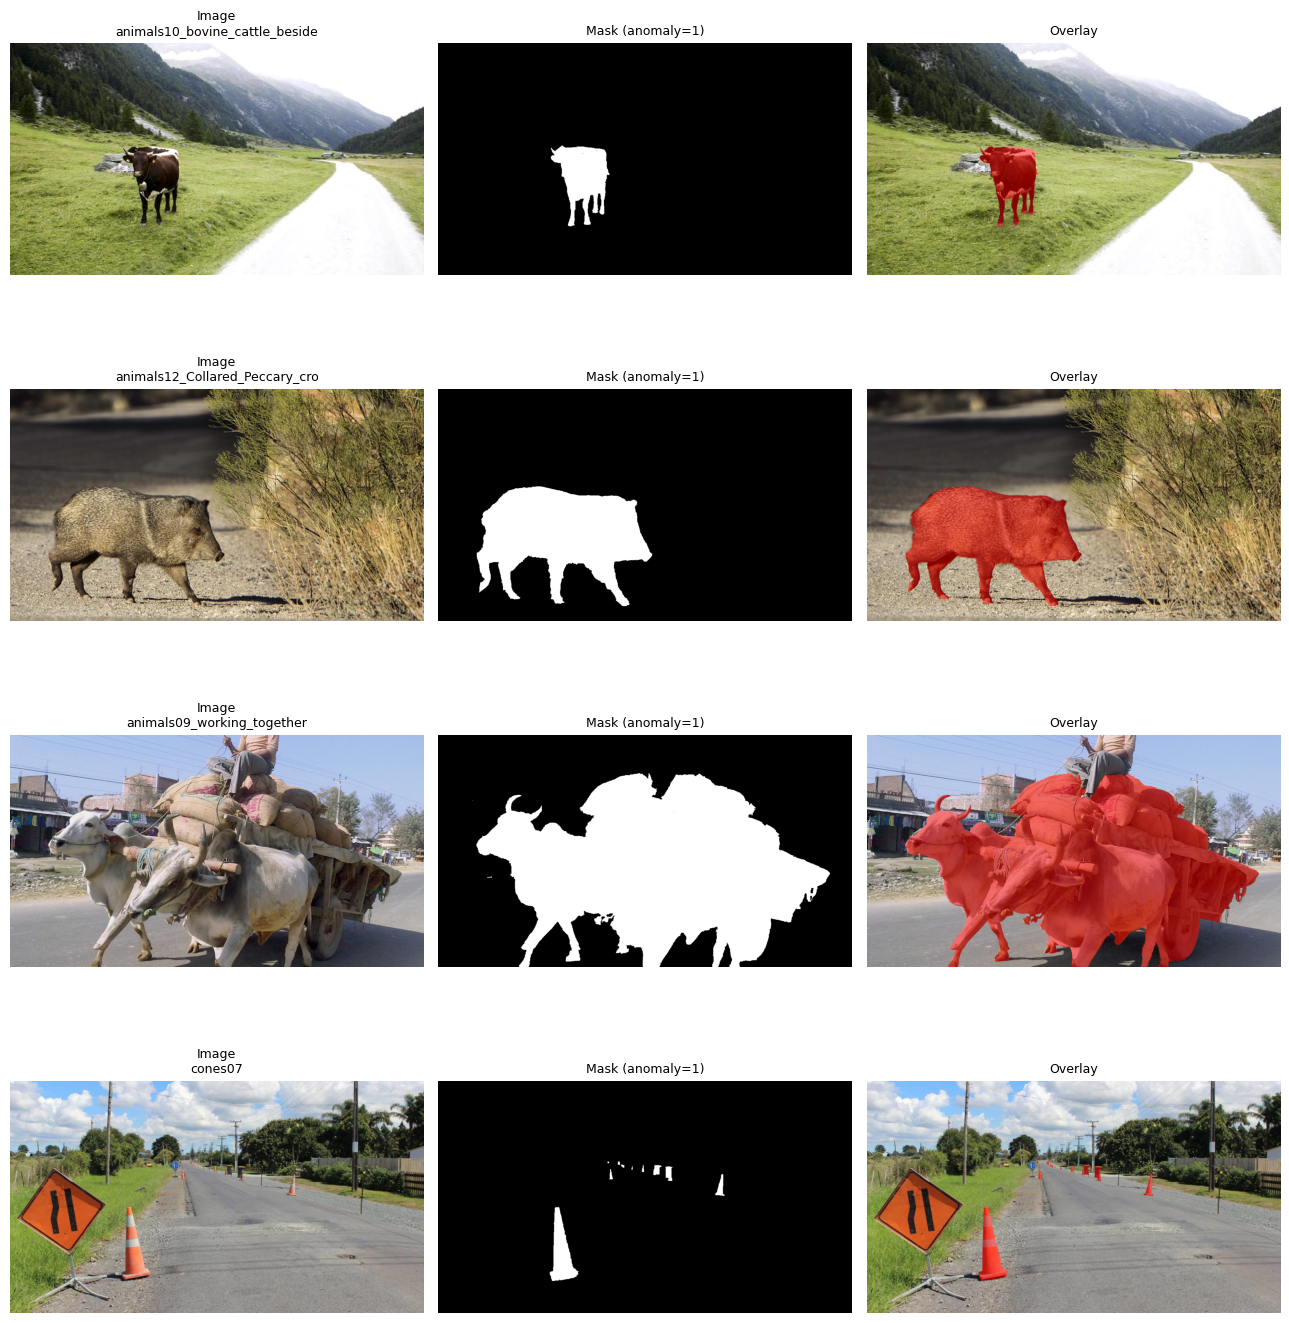

In [ ]:
def show(idx_list):
    fig, axes = plt.subplots(len(idx_list), 3, figsize=(13, 3.6*len(idx_list)))
    for ax_row, i in zip(axes, idx_list):
        r = df.iloc[i]
        img = np.array(Image.open(r["img"]).convert("RGB"))
        m = (np.array(Image.open(r["mask"])) == 2)
        ov = img.copy(); ov[m] = (0.5*ov[m] + 0.5*np.array([255,0,0])).astype(np.uint8)
        for ax, im, t in zip(ax_row, [img, m, ov], ["Image", "Mask (anomaly=1)", "Overlay"]):
            ax.imshow(im, cmap="gray" if t.startswith("Mask") else None)
            ax.set_title(f"{t}\n{r['name'][:30]}" if t=="Image" else t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

show(np.random.choice(len(df), 4, replace=False))

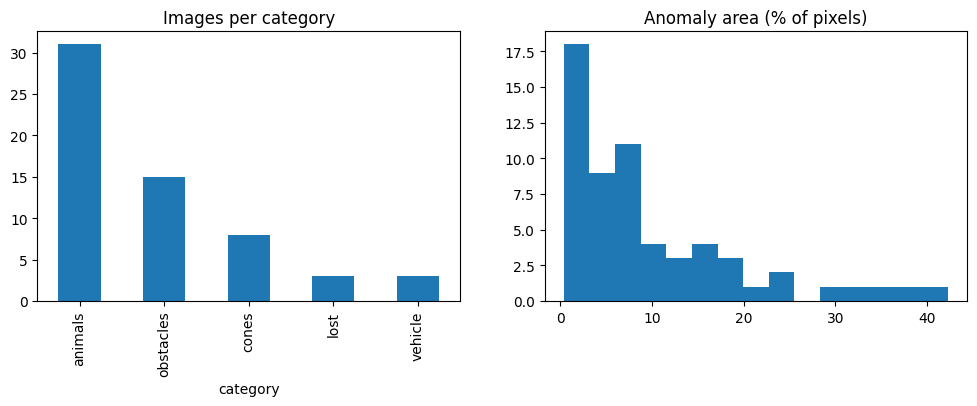

Overall anomaly pixel ratio: 9.85%


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.category.value_counts().plot.bar(ax=ax[0], title="Images per category")
ax[1].hist(df.anomaly_frac*100, bins=15); ax[1].set_title("Anomaly area (% of pixels)")
plt.show()
print("Overall anomaly pixel ratio: %.2f%%" % (df.anomaly_frac.mean()*100))

# Objective 2: Data preprocessing
Binary masks, resizing to 512x288, grouped and stratified train/val/test split, augmentation.

## 2.1 Loading and resizing

In [ ]:
W, H = 512, 288
X = np.zeros((len(df), H, W, 3), np.uint8)
Y = np.zeros((len(df), H, W), np.uint8)
for i, r in df.iterrows():
    X[i] = np.array(Image.open(r["img"]).convert("RGB").resize((W, H), Image.BILINEAR))
    m = (np.array(Image.open(r["mask"])) == 2).astype(np.uint8) * 255
    Y[i] = (np.array(Image.fromarray(m).resize((W, H), Image.NEAREST)) > 0)
print(X.shape, Y.shape, np.unique(Y))
print("anomaly ratio after resize: %.2f%%" % (Y.mean()*100))

(60, 288, 512, 3) (60, 288, 512) [0 1]
anomaly ratio after resize: 9.85%


## 2.2 Train/val/test split

In [ ]:
import re, warnings
from sklearn.model_selection import StratifiedGroupKFold
warnings.filterwarnings("ignore")

def group_key(n):
    rest = re.sub(r'^[a-z_]+?\d+_?', '', n)
    rest = re.sub(r'\d+$', '', rest)
    return rest if rest else n

df["category"] = df["category"].replace({"lost": "lost_tires"})
df["group"] = df["name"].apply(group_key)
# tiny categories merged ONLY for stratification
df["strata"] = df["category"].replace(
    {"cones": "other", "lost_tires": "other", "vehicle": "other"})

def make_split(seed):
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    folds = list(sg.split(X, df.strata, df.group))
    s = pd.Series("train", index=df.index)
    s.iloc[folds[0][1]] = "test"
    s.iloc[folds[1][1]] = "val"
    return s

def score(s):
    ct = pd.crosstab(df.category, s)
    missing = (ct[["val", "test"]] == 0).sum().sum()      # category absent from val/test
    am = df.groupby(s).anomaly_frac.mean()                # anomaly area similarity
    size_pen = abs((s == "val").sum() - 12) + abs((s == "test").sum() - 12)
    return missing * 10 + 50 * (abs(am["val"] - am["train"]) + abs(am["test"] - am["train"])) + size_pen * 0.3

# Pick the seed with the most balanced split (never looks at model results)
best_seed = min(range(200), key=lambda sd: score(make_split(sd)))
df["split"] = make_split(best_seed)
print("best seed:", best_seed)

train_idx = np.where(df.split == "train")[0]
val_idx   = np.where(df.split == "val")[0]
test_idx  = np.where(df.split == "test")[0]

print(pd.crosstab(df.category, df.split))
print(df.groupby("split").anomaly_frac.mean().round(3))
print("sizes:", len(train_idx), len(val_idx), len(test_idx))
print("groups in >1 split:", (df.groupby("group").split.nunique() > 1).sum())  # must be 0

best seed: 183
split       test  train  val
category                    
animals        4     21    6
cones          1      6    1
lost_tires     1      1    1
obstacles      5      5    5
vehicle        1      1    1
split
test     0.088
train    0.096
val      0.112
Name: anomaly_frac, dtype: float64
sizes: 34 14 12
groups in >1 split: 0


## 2.3 Augmentation (train only)

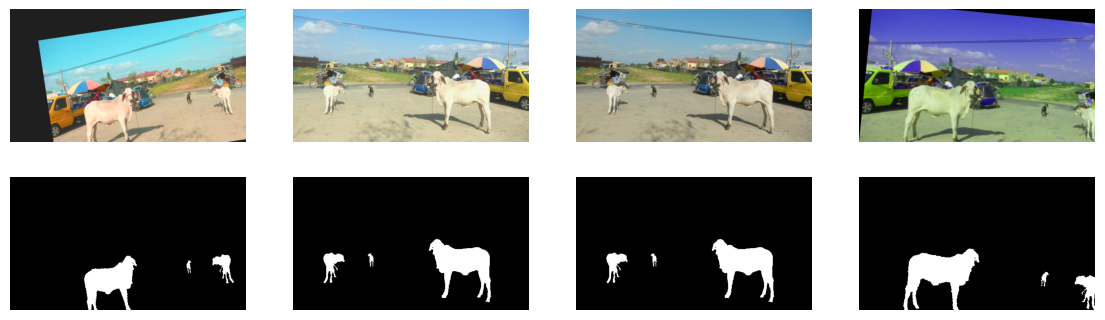

In [ ]:
import albumentations as A
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.8, 1.2), translate_percent=0.1, rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(p=0.5),
    A.HueSaturationValue(p=0.3),
])
i = train_idx[0]
fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for k in range(4):
    out = train_aug(image=X[i], mask=Y[i])
    ax[0, k].imshow(out["image"]); ax[1, k].imshow(out["mask"], cmap="gray")
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.show()

2.4 Classification labels (Objective 2)

In [ ]:
# Etiquette = anomaly category. "other" merges cones + lost tires + vehicles
# (lost tires and vehicles have only 1 training image each, too few to learn alone)
CLASSES = ["animals", "obstacles", "other"]
df["label"] = df["strata"].map({c: i for i, c in enumerate(CLASSES)})
y_cls = df["label"].values
print(pd.crosstab(df["strata"], df["split"]))

split      test  train  val
strata                     
animals       4     21    6
obstacles     5      5    5
other         3      8    3


# Objective 3: Model implementation
Four approaches are compared: U-Net from scratch, U-Net + ResNet34 (transfer learning),
DeepLabV3+ + ResNet34 (transfer learning) and a convolutional autoencoder.

[TEXT]  ## 3.0 Shared code: datasets and normalization

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)   # if "cpu": Runtime > Change runtime type > GPU

# Save the split so every experiment (and your report) uses the exact same one
df[["name", "category", "group", "split"]].to_csv("/content/split.csv", index=False)

# ImageNet normalization: needed later for pretrained encoders, so we use it from now on
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD  = np.array([0.229, 0.224, 0.225], np.float32)

class RoadDS(Dataset):
    def __init__(self, idx, aug=None):
        self.idx, self.aug = idx, aug
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; img, m = X[i], Y[i]
        if self.aug:                                  # augmentation only for training
            out = self.aug(image=img, mask=m); img, m = out["image"], out["mask"]
        img = (img.astype(np.float32) / 255 - MEAN) / STD
        return (torch.from_numpy(img.transpose(2, 0, 1)),           # (3,H,W)
                torch.from_numpy(m.astype(np.float32))[None])       # (1,H,W)

# Train indices repeated x4: each epoch sees 4 different augmented versions of each image
train_dl = DataLoader(RoadDS(np.repeat(train_idx, 4), train_aug), batch_size=4, shuffle=True)
val_dl   = DataLoader(RoadDS(val_idx),  batch_size=4)
test_dl  = DataLoader(RoadDS(test_idx), batch_size=4)   # not used until the final step
print(len(train_dl.dataset), len(val_dl.dataset), len(test_dl.dataset))

device: cuda
136 14 12


## 3.1 Baseline: U-Net from scratch
        Model, loss (BCE + Dice) and metrics (reused by all models), then training.

In [ ]:
# --- Small U-Net: encoder (downsample) + decoder (upsample) + skip connections ---
def block(i, o):                                      # 2 x (conv-BN-ReLU)
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class UNet(nn.Module):
    def __init__(self, c=(16, 32, 64, 128, 256)):
        super().__init__()
        self.enc, p = nn.ModuleList(), 3
        for ch in c: self.enc.append(block(p, ch)); p = ch
        self.up, self.dec = nn.ModuleList(), nn.ModuleList()
        for ch in reversed(c[:-1]):
            self.up.append(nn.ConvTranspose2d(p, ch, 2, stride=2))
            self.dec.append(block(ch * 2, ch)); p = ch
        self.out = nn.Conv2d(p, 1, 1)                 # 1 channel = anomaly logit
    def forward(self, x):
        skips = []
        for k, e in enumerate(self.enc):
            x = e(x)
            if k < len(self.enc) - 1: skips.append(x); x = F.max_pool2d(x, 2)
        for up, dec in zip(self.up, self.dec):
            x = up(x); x = dec(torch.cat([x, skips.pop()], 1))   # skip connection
        return self.out(x)

# --- Loss: BCE (pixel-wise) + Dice (overlap). Dice handles the ~10% class imbalance ---
def dice_loss(logits, y, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * y).sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + eps)).mean()
def loss_fn(logits, y):
    return F.binary_cross_entropy_with_logits(logits, y) + dice_loss(logits, y)

# --- Metrics: pixel counts accumulated over the whole set ---
@torch.no_grad()
def evaluate(model, loader, thr=0.5):
    model.eval(); tp = fp = fn = 0; per_img_iou = []; tot_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x); tot_loss += loss_fn(logits, y).item() * len(x)
        pred = (torch.sigmoid(logits) > thr).float()
        tp += (pred * y).sum().item(); fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
        for p, t in zip(pred, y):                     # IoU per image, then averaged
            u = ((p + t) > 0).sum().item()
            per_img_iou.append((p * t).sum().item() / u if u else 1.0)
    e = 1e-9
    return dict(loss=tot_loss / len(loader.dataset),
                precision=tp / (tp + fp + e), recall=tp / (tp + fn + e),
                f1=2 * tp / (2 * tp + fp + fn + e),
                iou=tp / (tp + fp + fn + e),          # global IoU
                dice=2 * tp / (2 * tp + fp + fn + e),
                mean_img_iou=float(np.mean(per_img_iou)))

training

In [ ]:
model = UNet().to(device)
print("params: %.2fM" % (sum(p.numel() for p in model.parameters()) / 1e6))
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS = 60
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)  # lr decays smoothly

hist, best_dice = [], -1
for ep in range(1, EPOCHS + 1):
    model.train(); run = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); l = loss_fn(model(x), y); l.backward(); opt.step()
        run += l.item() * len(x)
    sched.step()
    v = evaluate(model, val_dl)
    hist.append(dict(epoch=ep, train_loss=run / len(train_dl.dataset),
                     val_loss=v["loss"], val_dice=v["dice"], val_iou=v["iou"]))
    if v["dice"] > best_dice:                          # keep the best model on VAL
        best_dice = v["dice"]; torch.save(model.state_dict(), "/content/unet_baseline.pt")
    if ep % 5 == 0 or ep == 1:
        print(f"ep {ep:02d} | train {hist[-1]['train_loss']:.3f} | val {v['loss']:.3f} "
              f"| val dice {v['dice']:.3f} | val IoU {v['iou']:.3f}")
print("best val dice:", round(best_dice, 3))

params: 1.94M
ep 01 | train 1.307 | val 1.271 | val dice 0.134 | val IoU 0.072
ep 05 | train 0.978 | val 1.084 | val dice 0.406 | val IoU 0.255
ep 10 | train 0.825 | val 0.897 | val dice 0.528 | val IoU 0.359
ep 15 | train 0.725 | val 1.130 | val dice 0.454 | val IoU 0.294
ep 20 | train 0.661 | val 1.122 | val dice 0.428 | val IoU 0.272
ep 25 | train 0.595 | val 0.890 | val dice 0.503 | val IoU 0.336
ep 30 | train 0.490 | val 0.948 | val dice 0.443 | val IoU 0.285
ep 35 | train 0.501 | val 0.914 | val dice 0.465 | val IoU 0.303
ep 40 | train 0.403 | val 1.013 | val dice 0.380 | val IoU 0.235
ep 45 | train 0.374 | val 0.832 | val dice 0.494 | val IoU 0.328
ep 50 | train 0.347 | val 1.001 | val dice 0.365 | val IoU 0.223
ep 55 | train 0.315 | val 1.027 | val dice 0.367 | val IoU 0.225
ep 60 | train 0.332 | val 0.969 | val dice 0.411 | val IoU 0.259
best val dice: 0.528


curves, val metrics and predictions

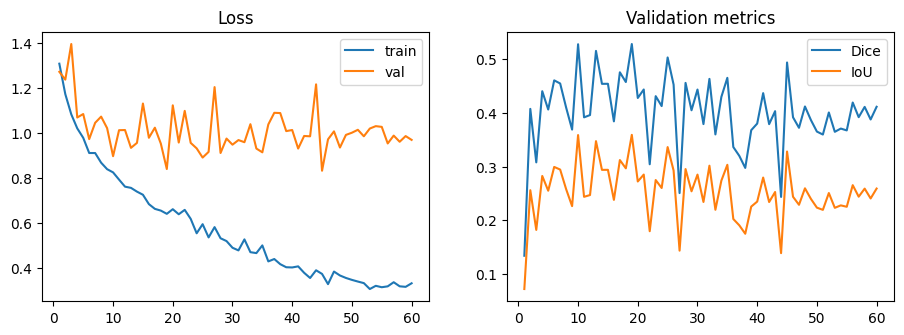

{'loss': 0.84, 'precision': 0.554, 'recall': 0.505, 'f1': 0.528, 'iou': 0.359, 'dice': 0.528, 'mean_img_iou': 0.389}


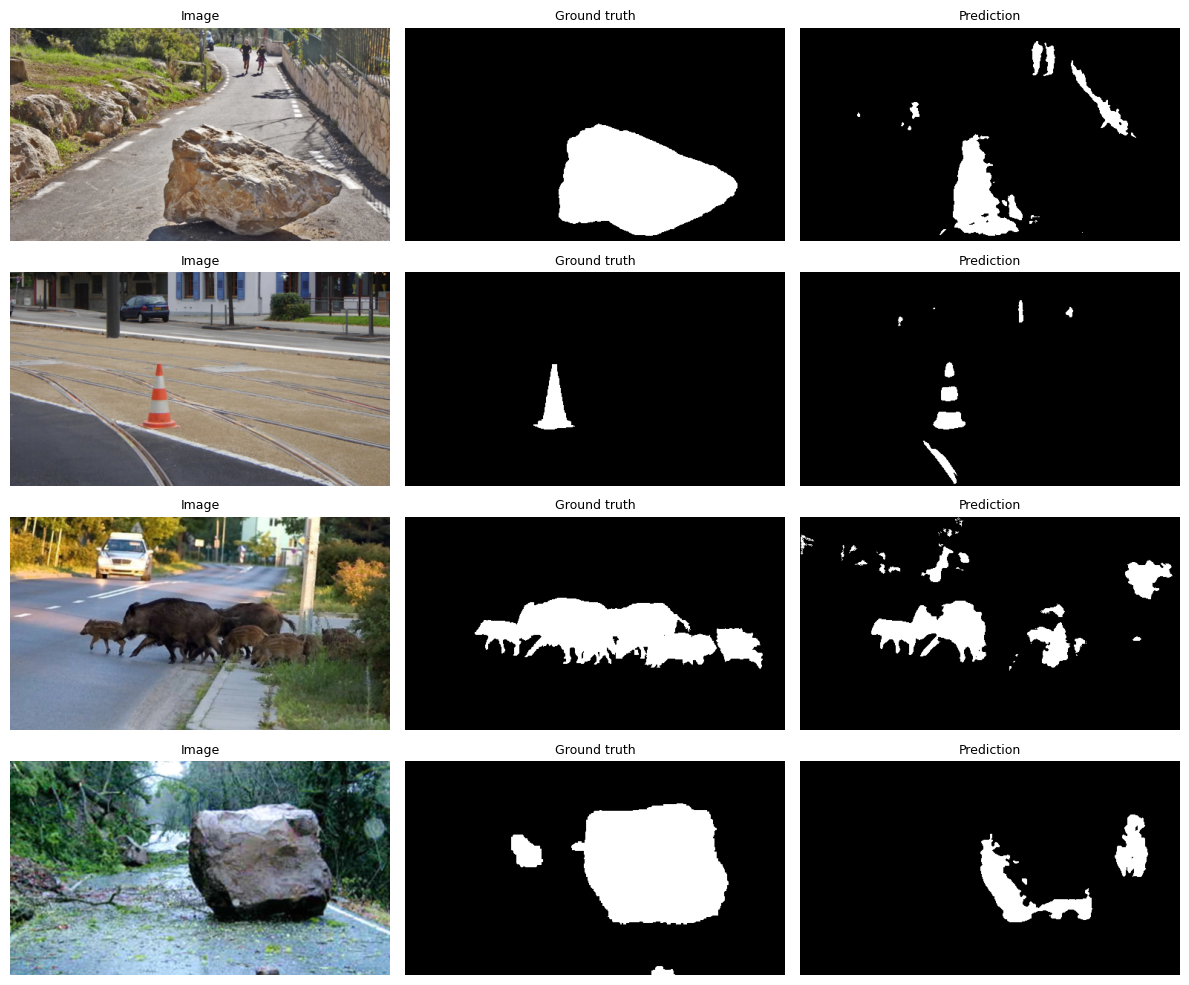

In [ ]:
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h.epoch, h.val_dice, label="Dice"); ax[1].plot(h.epoch, h.val_iou, label="IoU")
ax[1].set_title("Validation metrics"); ax[1].legend(); plt.show()

model.load_state_dict(torch.load("/content/unet_baseline.pt"))   # best epoch
print({k: round(v, 3) for k, v in evaluate(model, val_dl).items()})

# Predictions on validation images: input | ground truth | prediction
model.eval()
fig, axes = plt.subplots(4, 3, figsize=(12, 10))
for r, k in enumerate(np.random.choice(len(val_idx), 4, replace=False)):
    x, y = RoadDS(val_idx)[k]
    with torch.no_grad(): p = torch.sigmoid(model(x[None].to(device)))[0, 0].cpu().numpy()
    img = X[val_idx[k]]
    for a, im, t in zip(axes[r], [img, y[0], p > 0.5], ["Image", "Ground truth", "Prediction"]):
        a.imshow(im, cmap=None if t == "Image" else "gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 3.2 Transfer learning (pretrained ResNet34 encoder)

save the baseline result , install the lib

In [ ]:
# Store baseline val metrics so every model can be compared in one table later
model.load_state_dict(torch.load("/content/unet_baseline.pt"))
results = {"U-Net scratch": evaluate(model, val_dl)}
print({k: round(v, 3) for k, v in results["U-Net scratch"].items()})

!pip -q install segmentation-models-pytorch
import segmentation_models_pytorch as smp

{'loss': 0.84, 'precision': 0.554, 'recall': 0.505, 'f1': 0.528, 'iou': 0.359, 'dice': 0.528, 'mean_img_iou': 0.389}


reusable training function

In [ ]:
def train_model(net, name, epochs=40, lr_enc=1e-4, lr_dec=1e-3):
    net = net.to(device)
    # Differential learning rates: gentle for the pretrained encoder (keep its knowledge),
    # higher for the randomly initialized decoder/head
    enc = list(net.encoder.parameters()); enc_ids = {id(p) for p in enc}
    rest = [p for p in net.parameters() if id(p) not in enc_ids]
    opt = torch.optim.AdamW([{"params": enc, "lr": lr_enc},
                             {"params": rest, "lr": lr_dec}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist, best = [], -1
    for ep in range(1, epochs + 1):
        net.train(); run = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); l = loss_fn(net(x), y); l.backward(); opt.step()
            run += l.item() * len(x)
        sched.step()
        v = evaluate(net, val_dl)
        hist.append(dict(epoch=ep, train_loss=run / len(train_dl.dataset),
                         val_loss=v["loss"], val_dice=v["dice"], val_iou=v["iou"]))
        if v["dice"] > best:
            best = v["dice"]; torch.save(net.state_dict(), f"/content/{name}.pt")
        if ep % 5 == 0 or ep == 1:
            print(f"ep {ep:02d} | train {hist[-1]['train_loss']:.3f} | val {v['loss']:.3f} "
                  f"| val dice {v['dice']:.3f} | val IoU {v['iou']:.3f}")
    net.load_state_dict(torch.load(f"/content/{name}.pt"))   # reload the best epoch
    print("best val dice:", round(best, 3))
    return net, pd.DataFrame(hist)

train U-Net + ResNet34

In [ ]:
# encoder_weights="imagenet" downloads pretrained weights (needs internet, ~85 MB)
unet_r34 = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                    in_channels=3, classes=1)
print("params: %.1fM" % (sum(p.numel() for p in unet_r34.parameters()) / 1e6))
unet_r34, hist_r34 = train_model(unet_r34, "unet_resnet34", epochs=40)
results["U-Net + ResNet34"] = evaluate(unet_r34, val_dl)
print({k: round(v, 3) for k, v in results["U-Net + ResNet34"].items()})

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

params: 24.4M
ep 01 | train 0.922 | val 0.812 | val dice 0.699 | val IoU 0.537
ep 05 | train 0.254 | val 0.537 | val dice 0.767 | val IoU 0.622
ep 10 | train 0.155 | val 0.404 | val dice 0.831 | val IoU 0.711
ep 15 | train 0.112 | val 0.624 | val dice 0.749 | val IoU 0.599
ep 20 | train 0.086 | val 0.506 | val dice 0.787 | val IoU 0.649
ep 25 | train 0.078 | val 0.612 | val dice 0.748 | val IoU 0.597
ep 30 | train 0.069 | val 0.567 | val dice 0.777 | val IoU 0.635
ep 35 | train 0.067 | val 0.580 | val dice 0.774 | val IoU 0.631
ep 40 | train 0.065 | val 0.531 | val dice 0.793 | val IoU 0.657
best val dice: 0.88
{'loss': 0.34, 'precision': 0.905, 'recall': 0.855, 'f1': 0.88, 'iou': 0.785, 'dice': 0.88, 'mean_img_iou': 0.718}


comparison and predictions

                  loss  precision  recall     f1    iou   dice  mean_img_iou
U-Net scratch     0.84      0.554   0.505  0.528  0.359  0.528         0.389
U-Net + ResNet34  0.34      0.905   0.855  0.880  0.785  0.880         0.718


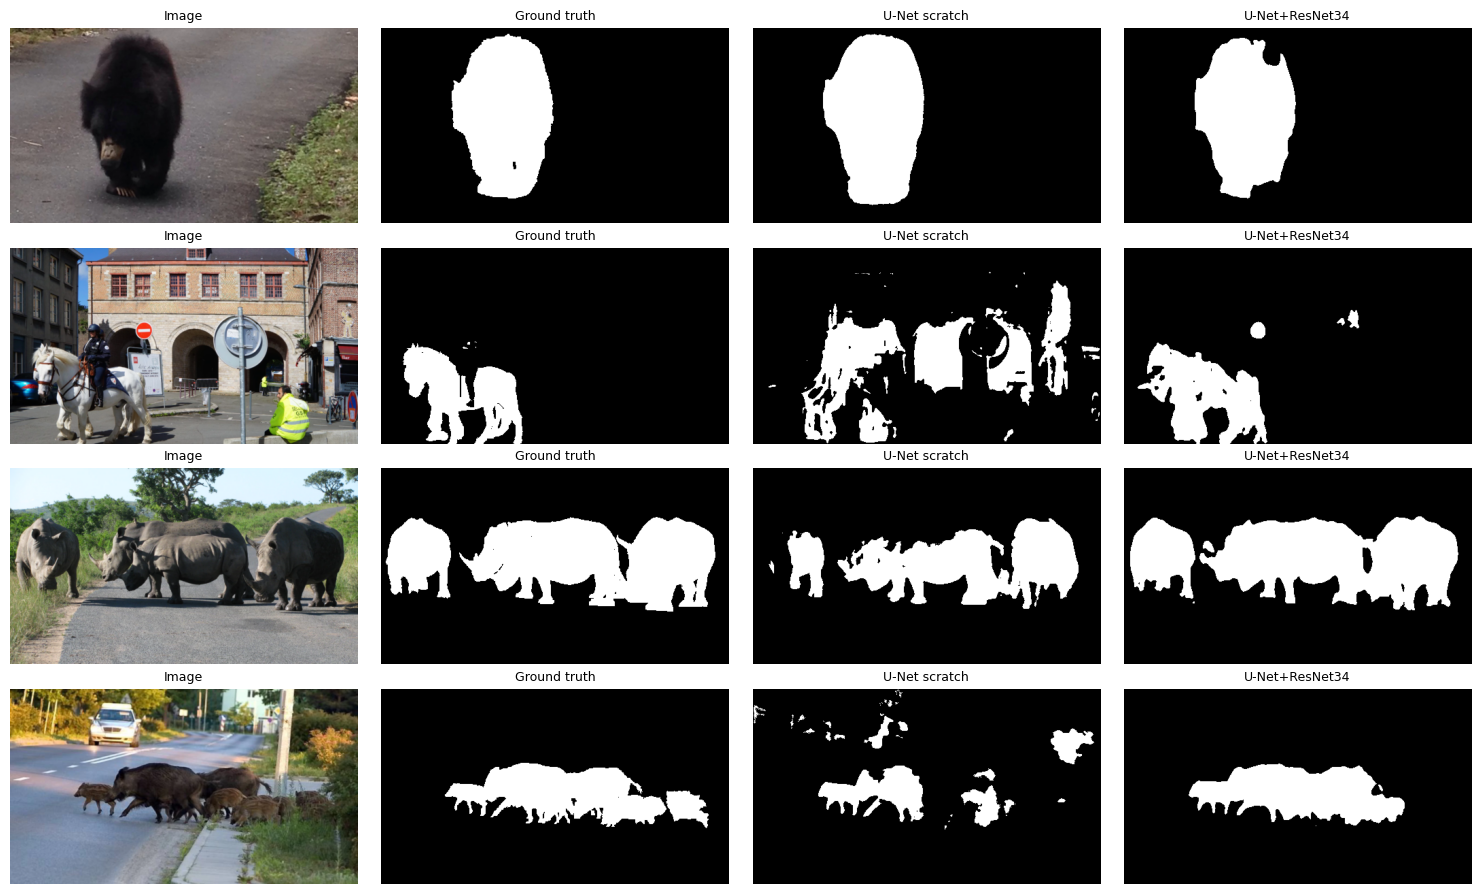

In [ ]:
print(pd.DataFrame(results).T.round(3))

unet_r34.eval(); model.eval()
fig, axes = plt.subplots(4, 4, figsize=(15, 9))
for r, k in enumerate(np.random.choice(len(val_idx), 4, replace=False)):
    x, y = RoadDS(val_idx)[k]
    with torch.no_grad():
        p1 = torch.sigmoid(model(x[None].to(device)))[0, 0].cpu().numpy()
        p2 = torch.sigmoid(unet_r34(x[None].to(device)))[0, 0].cpu().numpy()
    for a, im, t in zip(axes[r], [X[val_idx[k]], y[0], p1 > .5, p2 > .5],
                        ["Image", "Ground truth", "U-Net scratch", "U-Net+ResNet34"]):
        a.imshow(im, cmap=None if t == "Image" else "gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

 more approaches for the comparison

### 3.2.1 Second architecture: DeepLabV3+

In [ ]:
# Same encoder, different decoder (atrous/ASPP context) -> fair architecture comparison
deeplab = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights="imagenet",
                            in_channels=3, classes=1)
deeplab, hist_dl = train_model(deeplab, "deeplabv3p_resnet34", epochs=40)
results["DeepLabV3+ ResNet34"] = evaluate(deeplab, val_dl)
print(pd.DataFrame(results).T.round(3))

ep 01 | train 0.904 | val 0.646 | val dice 0.799 | val IoU 0.665
ep 05 | train 0.218 | val 0.343 | val dice 0.859 | val IoU 0.753
ep 10 | train 0.150 | val 0.378 | val dice 0.857 | val IoU 0.750
ep 15 | train 0.118 | val 0.337 | val dice 0.858 | val IoU 0.751
ep 20 | train 0.104 | val 0.303 | val dice 0.883 | val IoU 0.790
ep 25 | train 0.094 | val 0.323 | val dice 0.875 | val IoU 0.779
ep 30 | train 0.091 | val 0.314 | val dice 0.881 | val IoU 0.787
ep 35 | train 0.086 | val 0.328 | val dice 0.873 | val IoU 0.775
ep 40 | train 0.088 | val 0.330 | val dice 0.868 | val IoU 0.766
best val dice: 0.887
                      loss  precision  recall     f1    iou   dice  \
U-Net scratch        0.840      0.554   0.505  0.528  0.359  0.528   
U-Net + ResNet34     0.340      0.905   0.855  0.880  0.785  0.880   
DeepLabV3+ ResNet34  0.305      0.959   0.825  0.887  0.797  0.887   

                     mean_img_iou  
U-Net scratch               0.389  
U-Net + ResNet34            0.718  
DeepL

## 3.3 Autoencoder (reconstruction error)
        Trained on normal content only (anomaly pixels excluded from the loss).

In [ ]:
# Idea: train the AE to reconstruct NORMAL road content only. Anomalous objects are
# reconstructed badly -> high reconstruction error = anomaly score.
# We exclude anomaly pixels from the loss, so the AE never learns to rebuild them.
class ConvAE(nn.Module):
    def __init__(self):
        super().__init__()
        down = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU(True))
        up   = lambda i, o: nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.ReLU(True))
        self.enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), down(128, 128))  # /16
        self.bott = nn.Conv2d(128, 16, 1)      # tight bottleneck (16 channels)
        self.unb  = nn.Conv2d(16, 128, 1)
        self.dec = nn.Sequential(up(128, 128), up(128, 64), up(64, 32),
                                 nn.ConvTranspose2d(32, 3, 4, 2, 1))
    def forward(self, x):
        return self.dec(self.unb(self.bott(self.enc(x))))

ae = ConvAE().to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
for ep in range(1, 41):
    ae.train(); run = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        w = 1 - y                                       # 1 on normal pixels, 0 on anomalies
        loss = (((ae(x) - x) ** 2) * w).sum() / (w.sum() * 3 + 1e-6)   # masked MSE
        opt.zero_grad(); loss.backward(); opt.step(); run += loss.item() * len(x)
    if ep % 10 == 0 or ep == 1:
        print(f"ep {ep:02d} | masked recon loss {run/len(train_dl.dataset):.4f}")

ep 01 | masked recon loss 0.7226
ep 10 | masked recon loss 0.2042
ep 20 | masked recon loss 0.1637
ep 30 | masked recon loss 0.1526
ep 40 | masked recon loss 0.1346


anomaly maps, metrics and visualization

pixel AUROC (threshold-free): 0.564
                             loss  precision  recall     f1    iou   dice  \
U-Net scratch               0.840      0.554   0.505  0.528  0.359  0.528   
U-Net + ResNet34            0.340      0.905   0.855  0.880  0.785  0.880   
DeepLabV3+ ResNet34         0.305      0.959   0.825  0.887  0.797  0.887   
Autoencoder (recon. error)    NaN      0.131   0.581  0.214  0.120  0.214   

                            mean_img_iou  
U-Net scratch                      0.389  
U-Net + ResNet34                   0.718  
DeepLabV3+ ResNet34                0.790  
Autoencoder (recon. error)           NaN  


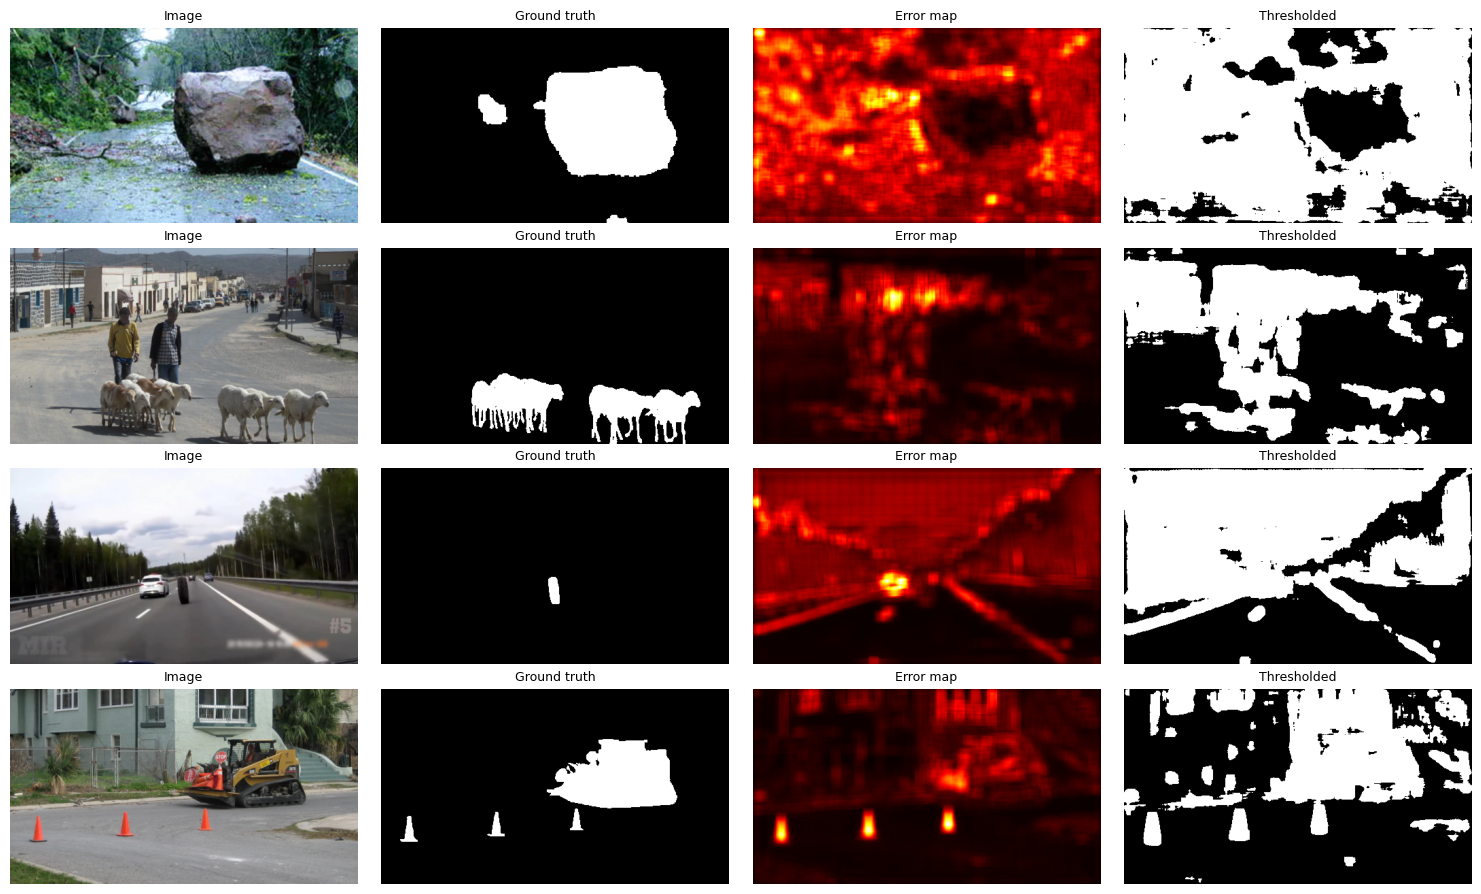

In [ ]:
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def ae_maps(idx):
    ae.eval(); E, G = [], []
    for x, y in DataLoader(RoadDS(idx), batch_size=4):
        x = x.to(device)
        err = ((ae(x) - x) ** 2).mean(1, keepdim=True)   # per-pixel reconstruction error
        err = F.avg_pool2d(err, 15, 1, 7)                # smoothing -> less noisy map
        E.append(err[:, 0].cpu().numpy()); G.append(y[:, 0].numpy())
    return np.concatenate(E), np.concatenate(G).astype(bool)

E, G = ae_maps(val_idx)
print("pixel AUROC (threshold-free): %.3f" % roc_auc_score(G.ravel()[::4], E.ravel()[::4]))

# Pick the threshold that maximizes Dice on VAL (to be reused as-is on test)
best = (-1, None)
for th in np.quantile(E, np.linspace(0.5, 0.99, 50)):
    P = E > th
    tp = (P & G).sum(); fp = (P & ~G).sum(); fn = (~P & G).sum()
    d = 2 * tp / (2 * tp + fp + fn + 1e-9)
    if d > best[0]: best = (d, th, tp, fp, fn)
d, ae_th, tp, fp, fn = best
results["Autoencoder (recon. error)"] = dict(
    precision=tp / (tp + fp), recall=tp / (tp + fn), f1=d, iou=tp / (tp + fp + fn), dice=d)
print(pd.DataFrame(results).T.round(3))

fig, axes = plt.subplots(4, 4, figsize=(15, 9))
for r, k in enumerate(np.random.choice(len(val_idx), 4, replace=False)):
    for a, im, t, cm in zip(axes[r], [X[val_idx[k]], G[k], E[k], E[k] > ae_th],
                            ["Image", "Ground truth", "Error map", "Thresholded"],
                            [None, "gray", "hot", "gray"]):
        a.imshow(im, cmap=cm); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print(pd.DataFrame(results).T[["precision","recall","f1","iou","dice"]].round(3))

                            precision  recall     f1    iou   dice
U-Net scratch                   0.554   0.505  0.528  0.359  0.528
U-Net + ResNet34                0.905   0.855  0.880  0.785  0.880
DeepLabV3+ ResNet34             0.959   0.825  0.887  0.797  0.887
Autoencoder (recon. error)      0.131   0.581  0.214  0.120  0.214


3.4 Classification models

In [ ]:
import torchvision
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

# Same geometric/color augmentation as segmentation, image only (no mask needed)
cls_aug = A.Compose([A.HorizontalFlip(p=0.5),
                     A.Affine(scale=(0.8, 1.2), translate_percent=0.1, rotate=(-10, 10), p=0.7),
                     A.RandomBrightnessContrast(p=0.5), A.HueSaturationValue(p=0.3)])

class ClsDS(Dataset):
    def __init__(self, idx, aug=None): self.idx, self.aug = idx, aug
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; img = X[i]
        if self.aug: img = self.aug(image=img)["image"]
        img = (img.astype(np.float32) / 255 - MEAN) / STD
        return torch.from_numpy(img.transpose(2, 0, 1)), int(y_cls[i])

cls_train = DataLoader(ClsDS(np.repeat(train_idx, 4), cls_aug), batch_size=8, shuffle=True)
cls_val   = DataLoader(ClsDS(val_idx),  batch_size=8)
cls_test  = DataLoader(ClsDS(test_idx), batch_size=8)

# Class weights compensate the imbalance (animals >> other)
cnt = np.bincount(y_cls[train_idx], minlength=3)
cls_w = torch.tensor(len(train_idx) / (3 * cnt), dtype=torch.float32).to(device)
crit = nn.CrossEntropyLoss(weight=cls_w)

# Model 1: ResNet34 pretrained on ImageNet, new 3-class head (transfer learning)
def resnet34_cls():
    m = torchvision.models.resnet34(weights="IMAGENET1K_V1")
    m.fc = nn.Linear(512, 3); return m

# Model 2: small CNN from scratch (baseline), reuses block() from the baseline U-Net
def small_cnn():
    return nn.Sequential(block(3, 16), nn.MaxPool2d(2), block(16, 32), nn.MaxPool2d(2),
                         block(32, 64), nn.MaxPool2d(2), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 3))

@torch.no_grad()
def predict(net, loader):
    net.eval(); P, T = [], []
    for x, t in loader:
        P += net(x.to(device)).argmax(1).cpu().tolist(); T += t.tolist()
    return np.array(P), np.array(T)

def fit_cls(net, name, opt, epochs=30):
    net = net.to(device); best = -1
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for ep in range(1, epochs + 1):
        net.train()
        for x, t in cls_train:
            x, t = x.to(device), t.to(device)
            opt.zero_grad(); crit(net(x), t).backward(); opt.step()
        sched.step()
        p, t = predict(net, cls_val)
        f1 = f1_score(t, p, average="macro")            # model selection on VAL
        if f1 > best: best = f1; torch.save(net.state_dict(), f"/content/{name}.pt")
        if ep % 10 == 0: print(f"{name} ep {ep} | val acc {accuracy_score(t, p):.3f} | val macro-F1 {f1:.3f}")
    net.load_state_dict(torch.load(f"/content/{name}.pt"))
    print(f"{name}: best val macro-F1 {best:.3f}"); return net

torch.manual_seed(0)
r34 = resnet34_cls()
head = list(r34.fc.parameters()); hid = {id(p) for p in head}
opt = torch.optim.AdamW([{"params": [p for p in r34.parameters() if id(p) not in hid], "lr": 1e-4},
                         {"params": head, "lr": 1e-3}], weight_decay=1e-4)   # differential LR
cls_r34 = fit_cls(r34, "cls_resnet34", opt)

cnn = small_cnn()
cls_cnn = fit_cls(cnn, "cls_smallcnn", torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4))

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 184MB/s]


cls_resnet34 ep 10 | val acc 0.714 | val macro-F1 0.714
cls_resnet34 ep 20 | val acc 0.786 | val macro-F1 0.790
cls_resnet34 ep 30 | val acc 0.786 | val macro-F1 0.790
cls_resnet34: best val macro-F1 0.869
cls_smallcnn ep 10 | val acc 0.357 | val macro-F1 0.353
cls_smallcnn ep 20 | val acc 0.429 | val macro-F1 0.319
cls_smallcnn ep 30 | val acc 0.571 | val macro-F1 0.561
cls_smallcnn: best val macro-F1 0.592


# Objective 4: Performance evaluation
        Precision, Recall, F1, IoU, Dice. Test set used once; 5-fold CV measures variance.


## 4.1 Final test-set evaluation

In [ ]:
# Reload the best (val-selected) weights of each model
model.load_state_dict(torch.load("/content/unet_baseline.pt"))
unet_r34.load_state_dict(torch.load("/content/unet_resnet34.pt"))
deeplab.load_state_dict(torch.load("/content/deeplabv3p_resnet34.pt"))

nets = {"U-Net scratch": model, "U-Net + ResNet34": unet_r34, "DeepLabV3+ ResNet34": deeplab}
test_res = {n: evaluate(net, test_dl) for n, net in nets.items()}   # threshold 0.5

# Autoencoder: threshold fixed from VAL (ae_th), never re-tuned on test
Et, Gt = ae_maps(test_idx)
P = Et > ae_th
tp = (P & Gt).sum(); fp = (P & ~Gt).sum(); fn = (~P & Gt).sum()
test_res["Autoencoder (recon. error)"] = dict(
    precision=tp/(tp+fp), recall=tp/(tp+fn), f1=2*tp/(2*tp+fp+fn),
    iou=tp/(tp+fp+fn), dice=2*tp/(2*tp+fp+fn))
print("AE pixel AUROC (test): %.3f" % roc_auc_score(Gt.ravel()[::4], Et.ravel()[::4]))

test_table = pd.DataFrame(test_res).T[["precision","recall","f1","iou","dice"]].round(3)
print(test_table)

AE pixel AUROC (test): 0.660
                            precision  recall     f1    iou   dice
U-Net scratch                   0.671   0.524  0.589  0.417  0.589
U-Net + ResNet34                0.708   0.623  0.663  0.496  0.663
DeepLabV3+ ResNet34             0.930   0.648  0.764  0.618  0.764
Autoencoder (recon. error)      0.121   0.698  0.207  0.115  0.207


## 4.2 5-fold cross-validation

 cross-validation, (to make the evaluation trustworthy)

In [ ]:
import copy
# Rebuild the folds exactly as in Cell 6 (same seed -> fold 0 = current split)
sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=best_seed)
folds = list(sg.split(X, df.strata, df.group))

def fit(net, tr_dl, va_dl, epochs=30, lr_enc=1e-4, lr_dec=1e-3):
    net = net.to(device)
    enc_ids = {id(p) for p in net.encoder.parameters()}
    opt = torch.optim.AdamW(
        [{"params": list(net.encoder.parameters()), "lr": lr_enc},
         {"params": [p for p in net.parameters() if id(p) not in enc_ids], "lr": lr_dec}],
        weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state = -1, None
    for ep in range(epochs):
        net.train()
        for x, y in tr_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss_fn(net(x), y).backward(); opt.step()
        sched.step()
        d = evaluate(net, va_dl)["dice"]                     # model selection on VAL fold only
        if d > best: best, best_state = d, copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state)
    return net

archs = {
    "U-Net+ResNet34": lambda: smp.Unet("resnet34", encoder_weights="imagenet", classes=1),
    "DeepLabV3+":     lambda: smp.DeepLabV3Plus("resnet34", encoder_weights="imagenet", classes=1),
}
cv = []
for f in range(5):
    te, va = folds[f][1], folds[(f + 1) % 5][1]              # test fold, val fold
    tr = np.concatenate([folds[i][1] for i in range(5) if i not in (f, (f + 1) % 5)])
    tr_dl = DataLoader(RoadDS(np.repeat(tr, 4), train_aug), batch_size=4, shuffle=True)
    va_dl = DataLoader(RoadDS(va), batch_size=4)
    te_dl = DataLoader(RoadDS(te), batch_size=4)
    for name, ctor in archs.items():
        torch.manual_seed(f)
        r = evaluate(fit(ctor(), tr_dl, va_dl), te_dl)
        cv.append(dict(fold=f, model=name, n_test=len(te), precision=r["precision"],
                       recall=r["recall"], dice=r["dice"], iou=r["iou"]))
        print(f"fold {f} | {name:15s} | test dice {r['dice']:.3f} | IoU {r['iou']:.3f}")

cvdf = pd.DataFrame(cv)
print(cvdf.groupby("model")[["precision", "recall", "dice", "iou"]].agg(["mean", "std"]).round(3))

fold 0 | U-Net+ResNet34  | test dice 0.758 | IoU 0.611
fold 0 | DeepLabV3+      | test dice 0.769 | IoU 0.625
fold 1 | U-Net+ResNet34  | test dice 0.840 | IoU 0.725
fold 1 | DeepLabV3+      | test dice 0.817 | IoU 0.690
fold 2 | U-Net+ResNet34  | test dice 0.791 | IoU 0.654
fold 2 | DeepLabV3+      | test dice 0.744 | IoU 0.593
fold 3 | U-Net+ResNet34  | test dice 0.903 | IoU 0.823
fold 3 | DeepLabV3+      | test dice 0.896 | IoU 0.812
fold 4 | U-Net+ResNet34  | test dice 0.653 | IoU 0.484
fold 4 | DeepLabV3+      | test dice 0.765 | IoU 0.620
               precision        recall          dice           iou       
                    mean    std   mean    std   mean    std   mean    std
model                                                                    
DeepLabV3+         0.874  0.082  0.745  0.105  0.798  0.061  0.668  0.088
U-Net+ResNet34     0.839  0.157  0.764  0.103  0.789  0.094  0.659  0.126


4.3 Classification evaluation

In [ ]:
import shutil, os
out = "/content/drive/MyDrive/DL_project/outputs"; os.makedirs(out, exist_ok=True)

majority-class baseline accuracy: 0.333

Small CNN (scratch) | test acc 0.583 | macro-F1 0.552
              precision    recall  f1-score   support

     animals       0.67      1.00      0.80         4
   obstacles       1.00      0.40      0.57         5
       other       0.25      0.33      0.29         3

    accuracy                           0.58        12
   macro avg       0.64      0.58      0.55        12
weighted avg       0.70      0.58      0.58        12


ResNet34 (pretrained) | test acc 0.583 | macro-F1 0.556
              precision    recall  f1-score   support

     animals       0.80      1.00      0.89         4
   obstacles       1.00      0.20      0.33         5
       other       0.33      0.67      0.44         3

    accuracy                           0.58        12
   macro avg       0.71      0.62      0.56        12
weighted avg       0.77      0.58      0.55        12



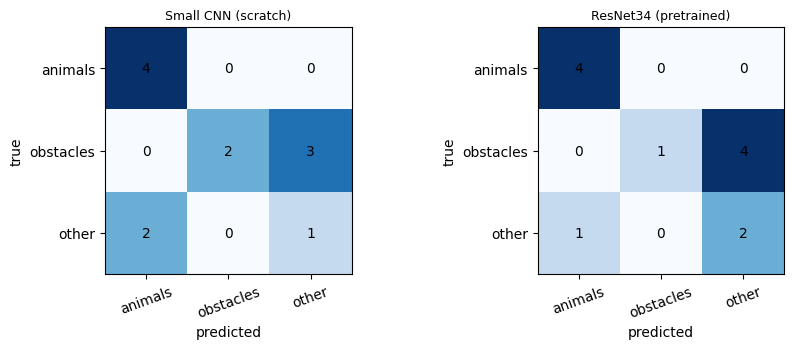

In [ ]:
maj = np.bincount(y_cls[train_idx]).argmax()           # "always predict the biggest class"
_, t_test = predict(cls_r34, cls_test)
print("majority-class baseline accuracy: %.3f" % (t_test == maj).mean())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, (name, net) in zip(ax, {"Small CNN (scratch)": cls_cnn, "ResNet34 (pretrained)": cls_r34}.items()):
    p, t = predict(net, cls_test)
    print(f"\n{name} | test acc {accuracy_score(t, p):.3f} | macro-F1 {f1_score(t, p, average='macro'):.3f}")
    print(classification_report(t, p, labels=[0, 1, 2], target_names=CLASSES, zero_division=0))
    a.imshow(confusion_matrix(t, p, labels=[0, 1, 2]), cmap="Blues")
    for (i, j), v in np.ndenumerate(confusion_matrix(t, p, labels=[0, 1, 2])): a.text(j, i, v, ha="center", va="center")
    a.set_xticks(range(3)); a.set_xticklabels(CLASSES, rotation=20); a.set_yticks(range(3)); a.set_yticklabels(CLASSES)
    a.set_title(name, fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig("/content/cls_confusion.png", dpi=150); shutil.copy("/content/cls_confusion.png", out); plt.show()

### 4.3.1 Classification cross-validation
With only 12 test images, one image changes accuracy by 8 points. We repeat training and
evaluation over the same 5 grouped, stratified folds used for segmentation (every image
is test once) and report mean +/- std of accuracy and macro-F1, next to the
majority-class baseline of each fold.

In [3]:
import os, re, json, copy, subprocess, sys, zipfile
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)

CLASSES = ["animals", "obstacles", "other"]
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

# ---- Rebuild data ONLY if the session was reset (X not in memory) ----
if "X" not in globals():
    from google.colab import drive; drive.mount('/content/drive')
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "albumentations"])
    from PIL import Image
    ZIP = "/content/drive/MyDrive/DL_project/RoadAnomaly.zip"; ROOT = "/content/data/RoadAnomaly"
    if not os.path.exists(ROOT): zipfile.ZipFile(ZIP).extractall("/content/data")
    names = [os.path.splitext(f)[0] for f in json.load(open(f"{ROOT}/frame_list.json"))]
    df = pd.DataFrame({"name": names})
    df["category"] = df["name"].apply(lambda n: n.split("_")[0].rstrip("0123456789")).replace({"lost": "lost_tires"})
    df["strata"] = df["category"].replace({"cones": "other", "lost_tires": "other", "vehicle": "other"})
    def group_key(n):
        r = re.sub(r'^[a-z_]+?\d+_?', '', n); r = re.sub(r'\d+$', '', r); return r if r else n
    df["group"] = df["name"].apply(group_key)
    X = np.stack([np.array(Image.open(f"{ROOT}/frames/{n}.webp").convert("RGB").resize((512, 288), Image.BILINEAR))
                  for n in names])
    df["label"] = df["strata"].map({c: i for i, c in enumerate(CLASSES)})
y_cls = df["label"].values
import albumentations as A

# ---- Same 5 folds as the segmentation cross-validation ----
seed = globals().get("best_seed", 183)
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, df.strata, df.group))

# ---- Definitions (same as section 3.4) ----
cls_aug = A.Compose([A.HorizontalFlip(p=0.5),
                     A.Affine(scale=(0.8, 1.2), translate_percent=0.1, rotate=(-10, 10), p=0.7),
                     A.RandomBrightnessContrast(p=0.5), A.HueSaturationValue(p=0.3)])
class ClsDS(Dataset):
    def __init__(self, idx, aug=None): self.idx, self.aug = idx, aug
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; img = X[i]
        if self.aug: img = self.aug(image=img)["image"]
        img = (img.astype(np.float32) / 255 - MEAN) / STD
        return torch.from_numpy(img.transpose(2, 0, 1)), int(y_cls[i])
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
def small_cnn():
    return nn.Sequential(block(3, 16), nn.MaxPool2d(2), block(16, 32), nn.MaxPool2d(2),
                         block(32, 64), nn.MaxPool2d(2), block(64, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 3))
def resnet34_cls():
    import torchvision
    m = torchvision.models.resnet34(weights="IMAGENET1K_V1"); m.fc = nn.Linear(512, 3); return m
@torch.no_grad()
def predict(net, loader):
    net.eval(); P, T = [], []
    for x, t in loader:
        P += net(x.to(device)).argmax(1).cpu().tolist(); T += t.tolist()
    return np.array(P), np.array(T)

def run_cls_fold(ctor, tr, va, te, pretrained, epochs=30):
    dl_tr = DataLoader(ClsDS(np.repeat(tr, 4), cls_aug), batch_size=8, shuffle=True)
    dl_va, dl_te = DataLoader(ClsDS(va), batch_size=8), DataLoader(ClsDS(te), batch_size=8)
    cnt = np.bincount(y_cls[tr], minlength=3)
    w = torch.tensor(len(tr) / (3 * np.maximum(cnt, 1)), dtype=torch.float32).to(device)
    crit = nn.CrossEntropyLoss(weight=w)                   # class weights computed on this fold's train set
    net = ctor().to(device)
    if pretrained:                                         # differential learning rates
        head = {id(p) for p in net.fc.parameters()}
        opt = torch.optim.AdamW([{"params": [p for p in net.parameters() if id(p) not in head], "lr": 1e-4},
                                 {"params": net.fc.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    else:
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, state = -1, None
    for ep in range(epochs):
        net.train()
        for x, t in dl_tr:
            x, t = x.to(device), t.to(device)
            opt.zero_grad(); crit(net(x), t).backward(); opt.step()
        sched.step()
        p, t = predict(net, dl_va)
        f1 = f1_score(t, p, average="macro", labels=[0, 1, 2], zero_division=0)
        if f1 > best: best, state = f1, copy.deepcopy(net.state_dict())   # selection on the VAL fold only
    net.load_state_dict(state)
    p, t = predict(net, dl_te)                              # TEST fold, used once
    return accuracy_score(t, p), f1_score(t, p, average="macro", labels=[0, 1, 2], zero_division=0)

res = []
for f in range(5):
    te, va = folds[f][1], folds[(f + 1) % 5][1]
    tr = np.concatenate([folds[i][1] for i in range(5) if i not in (f, (f + 1) % 5)])
    base = (y_cls[te] == np.bincount(y_cls[tr]).argmax()).mean()      # majority-class baseline
    for name, ctor, pre in [("Small CNN (scratch)", small_cnn, False), ("ResNet34 (pretrained)", resnet34_cls, True)]:
        torch.manual_seed(f)
        acc, f1 = run_cls_fold(ctor, tr, va, te, pre)
        res.append(dict(fold=f, model=name, acc=acc, macro_f1=f1, baseline_acc=base))
        print(f"fold {f} | {name:21s} | acc {acc:.3f} | macro-F1 {f1:.3f} | baseline {base:.3f}")

cls_cv = pd.DataFrame(res)
print(cls_cv.groupby("model")[["acc", "macro_f1", "baseline_acc"]].agg(["mean", "std"]).round(3))
pv = cls_cv.pivot(index="fold", columns="model", values="macro_f1")
print("ResNet34 better in", (pv["ResNet34 (pretrained)"] > pv["Small CNN (scratch)"]).sum(), "of 5 folds (macro-F1)")

device: cuda
Mounted at /content/drive
fold 0 | Small CNN (scratch)   | acc 0.417 | macro-F1 0.317 | baseline 0.333
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 210MB/s]


fold 0 | ResNet34 (pretrained) | acc 0.583 | macro-F1 0.544 | baseline 0.333
fold 1 | Small CNN (scratch)   | acc 0.357 | macro-F1 0.354 | baseline 0.429
fold 1 | ResNet34 (pretrained) | acc 0.857 | macro-F1 0.878 | baseline 0.429
fold 2 | Small CNN (scratch)   | acc 0.500 | macro-F1 0.427 | baseline 0.800
fold 2 | ResNet34 (pretrained) | acc 0.800 | macro-F1 0.786 | baseline 0.800
fold 3 | Small CNN (scratch)   | acc 0.364 | macro-F1 0.277 | baseline 0.545
fold 3 | ResNet34 (pretrained) | acc 0.909 | macro-F1 0.604 | baseline 0.545
fold 4 | Small CNN (scratch)   | acc 0.538 | macro-F1 0.528 | baseline 0.538
fold 4 | ResNet34 (pretrained) | acc 0.769 | macro-F1 0.692 | baseline 0.538
                         acc        macro_f1        baseline_acc       
                        mean    std     mean    std         mean    std
model                                                                  
ResNet34 (pretrained)  0.784  0.124    0.701  0.135        0.529  0.175
Small CNN (scratch)

**Result (5-fold CV, mean +/- std):** ResNet34 (pretrained) accuracy 0.784 +/- 0.124,
macro-F1 0.701 +/- 0.135; small CNN (scratch) accuracy 0.435 +/- 0.081, macro-F1
0.381 +/- 0.099; majority baseline accuracy 0.529 +/- 0.175. ResNet34 is better in all 5
folds. The small CNN is below the majority baseline on average, so it learned little from
34 training images. Test folds hold only 10 to 14 images, so fold scores vary widely
(ResNet34 macro-F1 from 0.54 to 0.88).

# Objective 5: Results analysis
        Per-image results, failure cases, comparison, strengths, limitations, improvements.

## 5.1 Per-image Dice and failure cases

                                                      name   category  U-Net scratch  U-Net + ResNet34  DeepLabV3+ ResNet34
                                        obstacles12_rocks2  obstacles           0.24              0.00                 0.05
                                        obstacles12_rocks6  obstacles           0.07              0.00                 0.03
                                obstacles07_czech_hedgehog  obstacles           0.72              0.07                 0.22
                                        obstacles12_rocks4  obstacles           0.04              0.09                 0.02
                              animals17_E6_near_Kvaenangen    animals           0.52              0.58                 0.76
                                        obstacles12_rocks5  obstacles           0.54              0.65                 0.62
                                               cones08_can      cones           0.36              0.82                 0.85
        

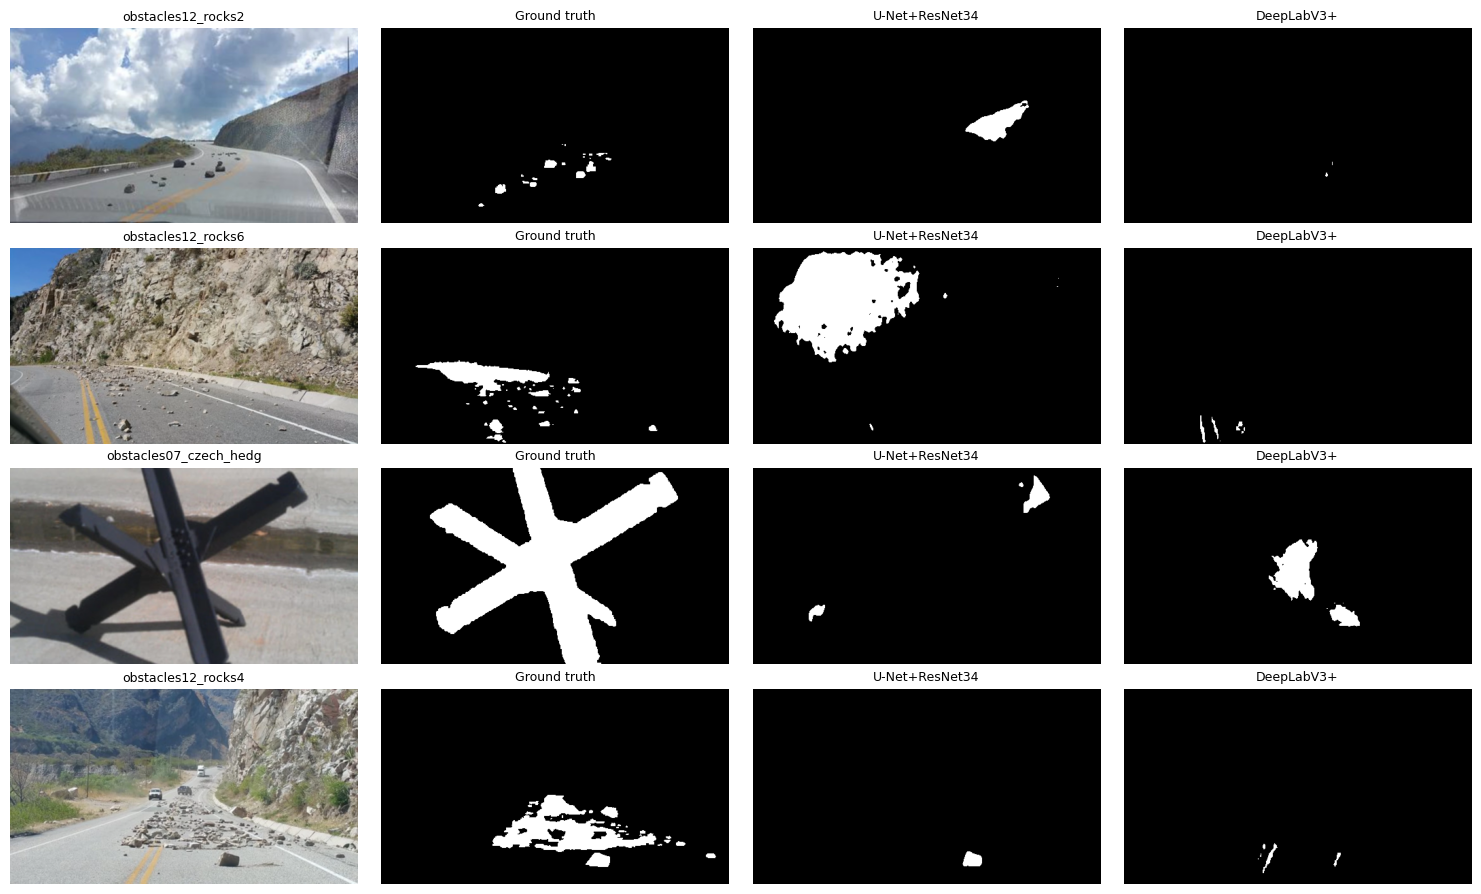

In [ ]:
@torch.no_grad()
def per_image_dice(net, idx):
    net.eval(); out = []
    for k in range(len(idx)):
        x, y = RoadDS(idx)[k]
        p = (torch.sigmoid(net(x[None].to(device))) > 0.5).float().cpu()[0]
        out.append((2 * (p * y).sum() / (p.sum() + y.sum() + 1e-9)).item())
    return out

pi = df.iloc[test_idx][["name", "category"]].copy()
for n in ["U-Net scratch", "U-Net + ResNet34", "DeepLabV3+ ResNet34"]:
    pi[n] = per_image_dice(nets[n], test_idx)
print(pi.round(2).sort_values("U-Net + ResNet34").to_string(index=False))

# The 4 hardest test images for the best model: image | GT | U-Net+R34 | DeepLabV3+
worst = np.argsort(pi["U-Net + ResNet34"].values)[:4]
fig, axes = plt.subplots(4, 4, figsize=(15, 9))
for r, k in enumerate(worst):
    x, y = RoadDS(test_idx)[k]
    with torch.no_grad():
        p1 = torch.sigmoid(unet_r34(x[None].to(device)))[0, 0].cpu().numpy()
        p2 = torch.sigmoid(deeplab(x[None].to(device)))[0, 0].cpu().numpy()
    for a, im, t in zip(axes[r], [X[test_idx[k]], y[0], p1 > .5, p2 > .5],
                        [pi.iloc[k]["name"][:22], "Ground truth", "U-Net+ResNet34", "DeepLabV3+"]):
        a.imshow(im, cmap=None if r >= 0 and t == pi.iloc[k]["name"][:22] else "gray")
        a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5.2 Model comparison

      DeepLabV3+  U-Net+ResNet34
fold                            
0          0.769           0.758
1          0.817           0.840
2          0.744           0.791
3          0.896           0.903
4          0.765           0.653
U-Net better in 3 of 5 folds


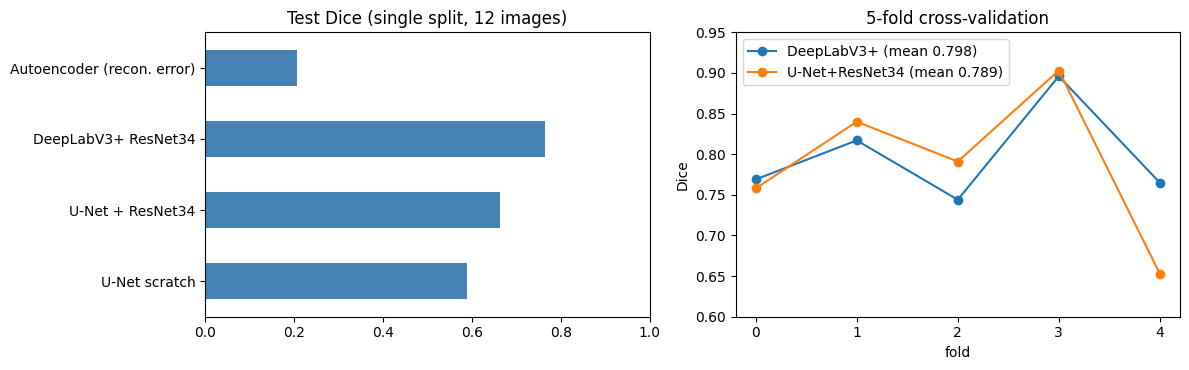

In [2]:
import pandas as pd, matplotlib.pyplot as plt

# Values copied from the outputs of cells 4.1 and 4.2 (re-run)
test_table = pd.DataFrame(
    {"dice": [0.589, 0.663, 0.764, 0.207]},
    index=["U-Net scratch", "U-Net + ResNet34", "DeepLabV3+ ResNet34", "Autoencoder (recon. error)"])
cv_pivot = pd.DataFrame(
    {"DeepLabV3+":     [0.769, 0.817, 0.744, 0.896, 0.765],
     "U-Net+ResNet34": [0.758, 0.840, 0.791, 0.903, 0.653]},
    index=pd.Index(range(5), name="fold"))

print(cv_pivot.round(3))
print("U-Net better in", (cv_pivot["U-Net+ResNet34"] > cv_pivot["DeepLabV3+"]).sum(), "of 5 folds")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
test_table["dice"].plot.barh(ax=ax[0], color="steelblue")
ax[0].set_xlim(0, 1); ax[0].set_title("Test Dice (single split, 12 images)")
for m, c in zip(cv_pivot.columns, ["tab:blue", "tab:orange"]):
    ax[1].plot(cv_pivot.index, cv_pivot[m], "o-", color=c,
               label=f"{m} (mean {cv_pivot[m].mean():.3f})")
ax[1].set_xticks(range(5)); ax[1].set_xlabel("fold"); ax[1].set_ylabel("Dice")
ax[1].set_ylim(0.6, 0.95); ax[1].set_title("5-fold cross-validation"); ax[1].legend()
plt.tight_layout(); plt.savefig("/content/comparison.png", dpi=150, bbox_inches="tight"); plt.show()

## 5.3 Save results to Drive


In [ ]:
import shutil, os
out = "/content/drive/MyDrive/DL_project/outputs"; os.makedirs(out, exist_ok=True)
cvdf.to_csv("/content/cv_results.csv", index=False)
test_table.to_csv("/content/test_results.csv")
for f in ["unet_baseline.pt", "unet_resnet34.pt", "deeplabv3p_resnet34.pt",
          "split.csv", "comparison.png", "cv_results.csv", "test_results.csv"]:
    shutil.copy(f"/content/{f}", out)
print(sorted(os.listdir(out)))

['comparison.png', 'cv_results.csv', 'deeplabv3p_resnet34.pt', 'split.csv', 'test_results.csv', 'unet_baseline.pt', 'unet_resnet34.pt']


## 5.4 Qualitative results on the test set

predictions on all 12 test images, ground truth vs prediction

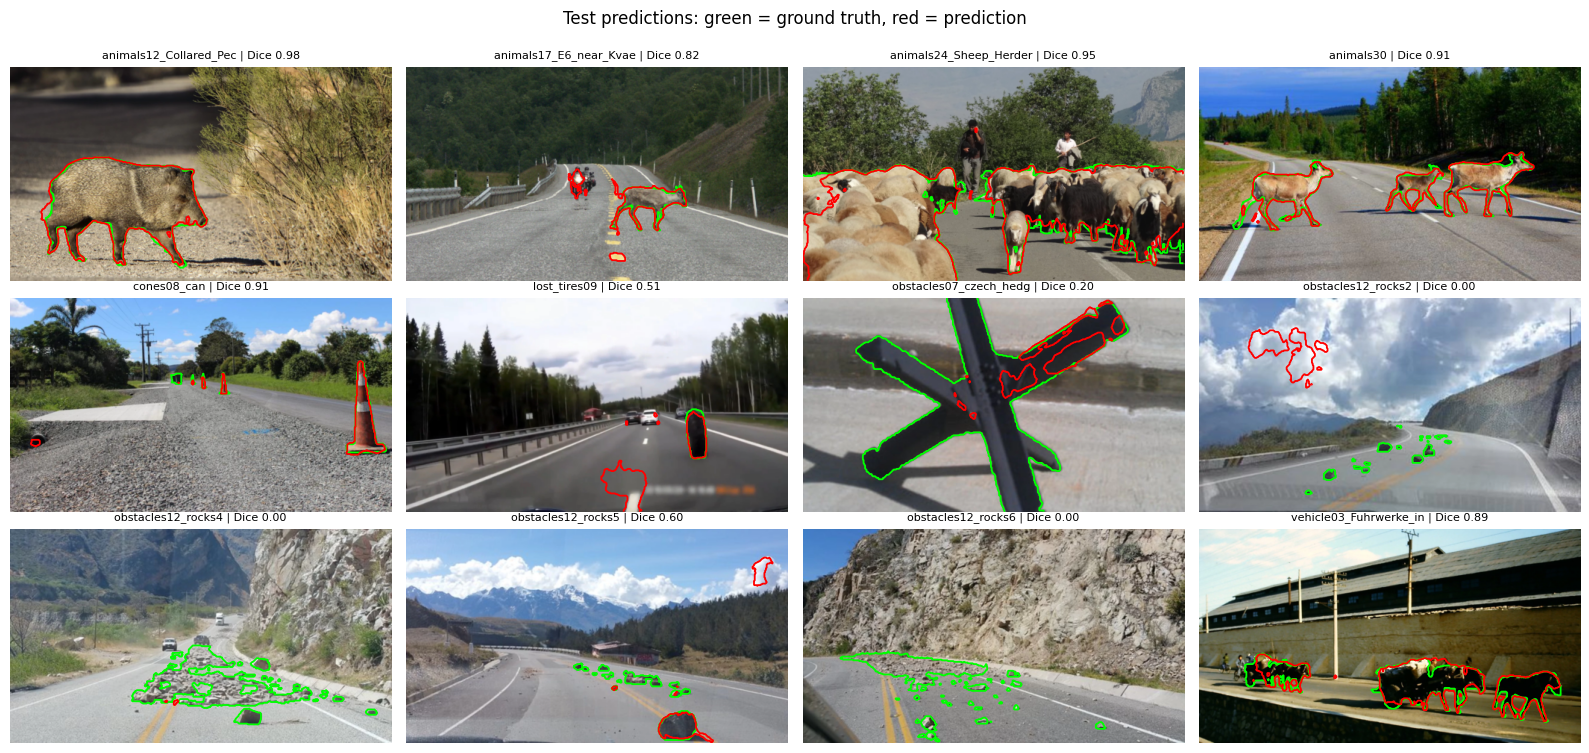

In [ ]:
# Green contour = ground truth, red contour = U-Net+ResNet34 prediction (threshold 0.5)
unet_r34.eval()
fig, axes = plt.subplots(3, 4, figsize=(16, 7.5))
for a, k in zip(axes.ravel(), range(len(test_idx))):
    x, y = RoadDS(test_idx)[k]
    with torch.no_grad():
        p = (torch.sigmoid(unet_r34(x[None].to(device)))[0, 0].cpu().numpy() > 0.5)
    g = y[0].numpy() > 0.5
    a.imshow(X[test_idx[k]])
    if g.any(): a.contour(g.astype(float), [0.5], colors="lime", linewidths=1.3)
    if p.any(): a.contour(p.astype(float), [0.5], colors="red", linewidths=1.3)
    dice = 2 * (p & g).sum() / (p.sum() + g.sum() + 1e-9)
    a.set_title(f"{df.iloc[test_idx[k]]['name'][:22]} | Dice {dice:.2f}", fontsize=8); a.axis("off")
plt.suptitle("Test predictions: green = ground truth, red = prediction", y=1.0)
plt.tight_layout()
plt.savefig("/content/test_predictions.png", dpi=150, bbox_inches="tight")
shutil.copy("/content/test_predictions.png", out)
plt.show()

## 5.5 Classification analysis
Cross-validation shows that **pretraining matters**: ResNet34 beats the small CNN in all 5
folds (accuracy 0.784 vs 0.435, macro-F1 0.701 vs 0.381), and the small CNN stays below the
majority baseline. The single test split (12 images) hid this difference, with both models at
58%, because it is the hardest fold: there, animals are recognized perfectly but obstacles
are mostly labeled "other". All 5 test obstacles are rock fields or the Czech hedgehog, a
scene type absent from training because the split is grouped by scene, the same cause as
the low segmentation scores on these images. The "other" class also mixes very different
objects (cones, tires, vehicles). With test folds of only 10 to 14 images, scores vary a lot
by fold, so the results show a clear trend, not a precise ranking.

# Conclusion

This notebook compared four approaches to pixel-level road anomaly detection on the
RoadAnomaly dataset (60 images), plus an image-level classification of the anomaly type.

**Segmentation, test set (12 images, one run)**

| Model | Precision | Recall | Dice | IoU |
|---|---|---|---|---|
| U-Net from scratch | 0.671 | 0.524 | 0.589 | 0.417 |
| U-Net + ResNet34 | 0.708 | 0.623 | 0.663 | 0.496 |
| DeepLabV3+ ResNet34 | 0.930 | 0.648 | 0.764 | 0.618 |
| Autoencoder | 0.121 | 0.698 | 0.207 | 0.115 |

**5-fold cross-validation (Dice, mean +/- std):** U-Net + ResNet34 **0.789 +/- 0.094**,
DeepLabV3+ **0.798 +/- 0.061**.

**Classification (anomaly type, 5-fold cross-validation, mean +/- std)**

| Model | Accuracy | Macro-F1 |
|---|---|---|
| Majority-class baseline | 0.529 +/- 0.175 | n/a |
| Small CNN (scratch) | 0.435 +/- 0.081 | 0.381 +/- 0.099 |
| ResNet34 (pretrained) | 0.784 +/- 0.124 | 0.701 +/- 0.135 |

**Main findings**
1. **Pretrained encoders help on most images.** DeepLabV3+ beats the scratch U-Net on 8 of
   12 test images and U-Net + ResNet34 on 9 of 12, with large gains on lost tires,
   cones and animals.
2. **U-Net and DeepLabV3+ are equivalent in practice.** The cross-validated gap is far
   below one standard deviation, and the order flipped between two runs.
3. **Single-run scores are noisy.** The same model on the same 12 images gave Dice 0.745,
   0.758 and 0.663 in three runs, so cross-validation is the reliable measure.
4. **The autoencoder is weak** (Dice 0.207, AUROC 0.660): reconstruction error reflects
   visual complexity, not objects that do not belong on the road.
5. **Precision is high (0.84 to 0.87) but recall is lower (0.75 to 0.76)**: the models are
   conservative. Realistic performance is about 0.79 Dice, from 0.65 to 0.90 by fold.
6. **Classification:** the pretrained ResNet34 beats a small CNN in all 5 folds (macro-F1
   0.70 vs 0.38), while the scratch CNN stays below the majority baseline. Animals are
   recognized well; obstacles such as rock fields are often labeled "other".

**Limitations**
- Very small dataset: high variance and strong dependence on which scenes are held out.
- Failure cases: scattered small rocks (Dice <= 0.09) and large unusual shapes (Czech
  hedgehog). All rock fields are in the test set and absent from training because the
  split is grouped by scene, which also explains the classification errors on obstacles.
- The supervised models learn the anomaly types seen in training and may not
  generalize to unseen objects (open-set problem, Lis et al., ICCV 2019).
- Classification on 12 images is only indicative: one image moves accuracy by 8 points.

**Possible improvements:** higher resolution for small objects, more data or synthetic
anomalies, recall-oriented losses (Focal, Tversky), test-time augmentation, ensembling,
open-set methods such as image resynthesis.